# 31B — Controlled GeoMAE / Spatial / Wind Ablation
## August-only exploratory experiment • identical architecture and supervised training budget

**Research questions.** Under matched conditions:

1. Does **masked self-supervised pretraining** help compared with training the **same ST-Wind architecture from scratch**?
2. Does providing **neighboring spatial tokens** help compared with only center-cell temporal tokens?
3. Does providing **wind U/V, speed, and explicit source→target wind exposure** help beyond non-wind spatiotemporal context?

**Four models (same architecture, loss, epochs, seeds, input window, target, and split):**

| Variant | Masked pretraining | Neighbor tokens visible | Wind features available |
|---|---|---|---|
| GeoMAE-T (neighbor-hidden) | Yes | No | No |
| GeoMAE-ST (wind-hidden) | Yes | Yes | No |
| GeoMAE-ST-Wind (proposed) | Yes | Yes | Yes |
| Transformer-ST-Wind scratch | **No** | Yes | Yes |

**Careful scope:** T and ST variants are *downstream input-availability ablations of the same ST-pretrained checkpoint*, not independently trained temporal-only and spatial-only pretraining runs. Wind-hidden also removes the wind channels at downstream time but the pretrained backbone previously saw them. Consequently the experiment estimates **downstream reliance on spatial/wind inputs**, not an isolated pretraining effect of each channel.

**Primary measure:** August Emerging-3 PR-AUC. **Secondary:** August overall and persistent-context PR-AUC; PR curves and paired date-block uncertainty intervals.

**No artificial winner:** every variant and every seed is reported. No choice based on September; August has already been used for development, so this is **exploratory ablation, not an untouched confirmation**.

In [2]:
# 1. Imports and reproducibility

from pathlib import Path
import copy
import math
import warnings
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 260)

SEEDS = [11, 22, 33]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("DEVICE:", DEVICE)
print("SEEDS :", SEEDS)

DEVICE: cpu
SEEDS : [11, 22, 33]


In [3]:
# 2. Resolve project files

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    data_path = (
        root
        / "data"
        / "processed"
        / "regional_025"
        / "karhut_ml_dataset_regional_025.csv"
    )

    checkpoint_path = (
        root
        / "model_results"
        / "geomae_spatiotemporal"
        / "t2"
        / "models"
        / "geomae_inspired_encoder.pt"
    )

    nb21_pred_path = (
        root
        / "model_results"
        / "regional_025_final_test"
        / "t2"
        / "exports"
        / "final_september_predictions.csv"
    )

    if (
        data_path.exists()
        and checkpoint_path.exists()
        and nb21_pred_path.exists()
    ):
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate regional dataset, NB24 GeoMAE checkpoint, "
        "and NB21 prediction export. Set PROJECT_ROOT manually if needed."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "regional_025"
    / "karhut_ml_dataset_regional_025.csv"
)

CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "geomae_spatiotemporal"
    / "t2"
    / "models"
    / "geomae_inspired_encoder.pt"
)

NB21_PRED_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_final_test"
    / "t2"
    / "exports"
    / "final_september_predictions.csv"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "geomae_controlled_ablation"
    / "t2"
)

EXPORT_DIR = RESULT_DIR / "exports"
FIGURE_DIR = RESULT_DIR / "figures"
MODEL_DIR = RESULT_DIR / "models"

for p in [
    EXPORT_DIR,
    FIGURE_DIR,
    MODEL_DIR,
]:
    p.mkdir(
        parents=True,
        exist_ok=True,
    )

print("PROJECT_ROOT:", PROJECT_ROOT)
print("RESULT_DIR  :", RESULT_DIR)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
RESULT_DIR  : c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_controlled_ablation\t2


In [4]:
# 3. Locked supervised configuration

# Development split
DEV_TRAIN_END = pd.Timestamp("2026-07-31")
DEV_VAL_START = pd.Timestamp("2026-08-01")
DEV_VAL_END = pd.Timestamp("2026-08-31")

# Training
BATCH_SIZE = 256
HEAD_WARMUP_EPOCHS = 2
MAX_FINETUNE_EPOCHS = 14
ONLINE_UPDATE_EPOCHS = 1

ENCODER_LR = 1e-4
HEAD_LR = 5e-4
WEIGHT_DECAY = 1e-4
DROPOUT = 0.20

# Task emphasis locked before seeing NB31 result.
# Emerging-3 is the primary task-specific subgroup.
LOSS_GENERAL_WEIGHT = 0.25
LOSS_EMERGING_WEIGHT = 0.50
LOSS_PERSISTENT_WEIGHT = 0.25

# Wind context
WIND_CONTEXT_DAYS = 3
WIND_DISTANCE_SCALE_KM = 50.0
MIN_WIND_SPEED = 0.5

print("Primary selection metric: August Emerging-3 PR-AUC")
print("Secondary metric       : August overall PR-AUC")
print("Max fine-tune epochs   :", MAX_FINETUNE_EPOCHS)

Primary selection metric: August Emerging-3 PR-AUC
Secondary metric       : August overall PR-AUC
Max fine-tune epochs   : 14


In [5]:
# 4. Load checkpoint and dataset

try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False,
    )
except TypeError:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
    )

TOKEN_FEATURES = list(
    checkpoint["token_features"]
)

FEATURE_MEAN = {
    k: float(v)
    for k, v
    in checkpoint["feature_mean"].items()
}

FEATURE_STD = {
    k: float(v)
    for k, v
    in checkpoint["feature_std"].items()
}

TEMPORAL_DAYS = int(
    checkpoint["temporal_days"]
)

SPATIAL_OFFSETS = [
    tuple(x)
    for x in checkpoint["spatial_offsets"]
]

CENTER_TOKEN_INDEX = int(
    checkpoint["center_token_index"]
)

PRETRAIN_END = pd.Timestamp(
    checkpoint["pretrain_end"]
)

GRID_STEP = 0.25
N_SPATIAL = len(SPATIAL_OFFSETS)
N_TOKENS = TEMPORAL_DAYS * N_SPATIAL

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["date"],
)

df = (
    df
    .sort_values(["date", "cell_id"])
    .reset_index(drop=True)
)

df["fire_count_log1p"] = np.log1p(
    pd.to_numeric(
        df["fire_count"],
        errors="coerce",
    ).clip(lower=0)
)

df["frp_sum_log1p"] = np.log1p(
    pd.to_numeric(
        df["frp_sum"],
        errors="coerce",
    ).clip(lower=0)
)

required = {
    "date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "target_fire_active_t1",
    "active_days_prev3_incl_t",
    "fire_active",
    "fire_count",
    "frp_sum",
    "wind_u_mean",
    "wind_v_mean",
    *TOKEN_FEATURES,
}

missing = sorted(
    required - set(df.columns)
)

if missing:
    raise ValueError(
        "Missing required columns:\n"
        + "\n".join(f"- {c}" for c in missing)
    )

print("Token features:", TOKEN_FEATURES)
print("Pretrain end  :", PRETRAIN_END.date())
print("Rows          :", len(df))
print("Cells         :", df["cell_id"].nunique())

Token features: ['temperature_mean', 'temperature_max', 'relative_humidity_mean', 'precipitation_sum', 'boundary_layer_height_mean', 'vapour_pressure_deficit_mean', 'wind_speed_mean', 'wind_speed_max', 'wind_u_mean', 'wind_v_mean', 'fire_active', 'fire_count_log1p', 'frp_sum_log1p']
Pretrain end  : 2026-07-31
Rows          : 16625
Cells         : 133


## Explicit wind-aware spatial context

For every target center cell and each of the last three observed days:

1. inspect the eight neighboring 0.25° cells;
2. take the source-cell wind vector;
3. compare it with the geographic direction **source → target**;
4. keep only the positive alignment component;
5. weight neighbor hotspot activity by:
   - positive wind alignment;
   - distance decay.

This creates physically interpretable predictive context such as:

- aligned neighboring fire-active exposure;
- aligned detection-count exposure;
- aligned FRP exposure;
- nearby activity independent of wind.

It is still interpreted as **predictive spatial-wind association**, not proof of physical flame spread.

In [6]:
# 5. Geometry helpers

EARTH_RADIUS_KM = 6371.0088

def haversine_km(
    lat1,
    lon1,
    lat2,
    lon2,
):
    lat1 = np.radians(
        np.asarray(lat1, dtype=float)
    )
    lon1 = np.radians(
        np.asarray(lon1, dtype=float)
    )
    lat2 = np.radians(
        np.asarray(lat2, dtype=float)
    )
    lon2 = np.radians(
        np.asarray(lon2, dtype=float)
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2.0) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2.0) ** 2
    )

    return (
        2.0
        * EARTH_RADIUS_KM
        * np.arcsin(
            np.sqrt(
                np.clip(
                    a,
                    0.0,
                    1.0,
                )
            )
        )
    )


def source_to_target_unit(
    source_lat,
    source_lon,
    target_lat,
    target_lon,
):
    mean_lat_rad = np.radians(
        (
            float(source_lat)
            + float(target_lat)
        )
        / 2.0
    )

    east_km = (
        (
            float(target_lon)
            - float(source_lon)
        )
        * 111.320
        * np.cos(mean_lat_rad)
    )

    north_km = (
        (
            float(target_lat)
            - float(source_lat)
        )
        * 110.574
    )

    norm = float(
        np.hypot(
            east_km,
            north_km,
        )
    )

    if norm == 0:
        return np.nan, np.nan

    return (
        east_km / norm,
        north_km / norm,
    )


def positive_wind_alignment(
    u,
    v,
    east_unit,
    north_unit,
):
    speed = float(
        np.hypot(
            u,
            v,
        )
    )

    if (
        not np.isfinite(speed)
        or speed < MIN_WIND_SPEED
        or not np.isfinite(east_unit)
        or not np.isfinite(north_unit)
    ):
        return 0.0

    cosine = (
        float(u) * float(east_unit)
        + float(v) * float(north_unit)
    ) / speed

    return float(
        max(
            cosine,
            0.0,
        )
    )

In [7]:
# 6. Recreate NB24 normalization and row lookup

z_cols = []

for col in TOKEN_FEATURES:
    z_col = f"z__{col}"

    mean = FEATURE_MEAN[col]
    std = FEATURE_STD[col]

    if (
        not np.isfinite(std)
        or std == 0
    ):
        std = 1.0

    df[z_col] = (
        pd.to_numeric(
            df[col],
            errors="coerce",
        )
        - mean
    ) / std

    z_cols.append(z_col)

z_matrix = (
    df[z_cols]
    .to_numpy(dtype=np.float32)
)

valid_vector = np.isfinite(
    z_matrix
).all(axis=1)

work = df.copy()

work["lat_key"] = (
    work["grid_lat"]
    .round(3)
)

work["lon_key"] = (
    work["grid_lon"]
    .round(3)
)

row_lookup = {
    (
        pd.Timestamp(row.date),
        round(float(row.lat_key), 3),
        round(float(row.lon_key), 3),
    ): idx
    for idx, row
    in work[
        [
            "date",
            "lat_key",
            "lon_key",
        ]
    ].iterrows()
}

raw_fire_active = (
    pd.to_numeric(
        work["fire_active"],
        errors="coerce",
    )
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

raw_fire_count_log = np.log1p(
    pd.to_numeric(
        work["fire_count"],
        errors="coerce",
    )
    .fillna(0)
    .clip(lower=0)
    .to_numpy(dtype=np.float32)
)

raw_frp_log = np.log1p(
    pd.to_numeric(
        work["frp_sum"],
        errors="coerce",
    )
    .fillna(0)
    .clip(lower=0)
    .to_numpy(dtype=np.float32)
)

raw_wind_u = (
    pd.to_numeric(
        work["wind_u_mean"],
        errors="coerce",
    )
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

raw_wind_v = (
    pd.to_numeric(
        work["wind_v_mean"],
        errors="coerce",
    )
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

print("Normalized token matrix:", z_matrix.shape)

Normalized token matrix: (16625, 13)


In [8]:
# 7. Patch + explicit wind-context builder

WIND_FEATURE_NAMES = []

for lag in range(WIND_CONTEXT_DAYS):
    WIND_FEATURE_NAMES.extend(
        [
            f"aligned_active_lag{lag}",
            f"aligned_count_lag{lag}",
            f"aligned_frp_lag{lag}",
            f"near_active_lag{lag}",
        ]
    )

N_WIND_FEATURES = len(
    WIND_FEATURE_NAMES
)

def build_sample(
    center_date,
    center_lat,
    center_lon,
):
    x = np.zeros(
        (
            N_TOKENS,
            len(TOKEN_FEATURES),
        ),
        dtype=np.float32,
    )

    valid = np.zeros(
        N_TOKENS,
        dtype=bool,
    )

    token_idx = 0

    for day_back in range(
        TEMPORAL_DAYS - 1,
        -1,
        -1,
    ):
        token_date = (
            pd.Timestamp(center_date)
            - pd.Timedelta(days=day_back)
        )

        for dx, dy in SPATIAL_OFFSETS:
            lat = round(
                float(
                    center_lat
                    + dy * GRID_STEP
                ),
                3,
            )

            lon = round(
                float(
                    center_lon
                    + dx * GRID_STEP
                ),
                3,
            )

            idx = row_lookup.get(
                (
                    token_date,
                    lat,
                    lon,
                )
            )

            if (
                idx is not None
                and valid_vector[idx]
            ):
                x[token_idx] = (
                    z_matrix[idx]
                )
                valid[token_idx] = True

            token_idx += 1

    wind_features = []

    for lag in range(
        WIND_CONTEXT_DAYS
    ):
        source_date = (
            pd.Timestamp(center_date)
            - pd.Timedelta(days=lag)
        )

        aligned_active = 0.0
        aligned_count = 0.0
        aligned_frp = 0.0
        near_active = 0.0

        for dx, dy in SPATIAL_OFFSETS:
            if dx == 0 and dy == 0:
                continue

            source_lat = round(
                float(
                    center_lat
                    + dy * GRID_STEP
                ),
                3,
            )

            source_lon = round(
                float(
                    center_lon
                    + dx * GRID_STEP
                ),
                3,
            )

            idx = row_lookup.get(
                (
                    source_date,
                    source_lat,
                    source_lon,
                )
            )

            if idx is None:
                continue

            distance = float(
                haversine_km(
                    source_lat,
                    source_lon,
                    center_lat,
                    center_lon,
                )
            )

            distance_weight = float(
                np.exp(
                    -distance
                    / WIND_DISTANCE_SCALE_KM
                )
            )

            east_unit, north_unit = (
                source_to_target_unit(
                    source_lat,
                    source_lon,
                    center_lat,
                    center_lon,
                )
            )

            alignment = (
                positive_wind_alignment(
                    raw_wind_u[idx],
                    raw_wind_v[idx],
                    east_unit,
                    north_unit,
                )
            )

            wind_weight = (
                alignment
                * distance_weight
            )

            active = float(
                raw_fire_active[idx]
            )

            aligned_active += (
                active
                * wind_weight
            )

            aligned_count += (
                float(
                    raw_fire_count_log[idx]
                )
                * wind_weight
            )

            aligned_frp += (
                float(
                    raw_frp_log[idx]
                )
                * wind_weight
            )

            near_active += (
                active
                * distance_weight
            )

        wind_features.extend(
            [
                aligned_active,
                aligned_count,
                aligned_frp,
                near_active,
            ]
        )

    return (
        x,
        valid,
        np.asarray(
            wind_features,
            dtype=np.float32,
        ),
    )


print("Explicit wind features:", WIND_FEATURE_NAMES)

Explicit wind features: ['aligned_active_lag0', 'aligned_count_lag0', 'aligned_frp_lag0', 'near_active_lag0', 'aligned_active_lag1', 'aligned_count_lag1', 'aligned_frp_lag1', 'near_active_lag1', 'aligned_active_lag2', 'aligned_count_lag2', 'aligned_frp_lag2', 'near_active_lag2']


In [9]:
# 8. Build all supervised samples

min_sample_date = (
    work["date"].min()
    + pd.Timedelta(
        days=TEMPORAL_DAYS - 1
    )
)

meta_source = (
    work[
        (
            work["date"]
            >= min_sample_date
        )
        &
        (
            work[
                "target_fire_active_t1"
            ].notna()
        )
    ][
        [
            "date",
            "cell_id",
            "grid_lat",
            "grid_lon",
            "target_fire_active_t1",
            "active_days_prev3_incl_t",
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

patches = []
valid_masks = []
wind_context = []
meta_rows = []

for row in meta_source.itertuples(
    index=False
):
    x, valid, wind = build_sample(
        row.date,
        row.grid_lat,
        row.grid_lon,
    )

    if not valid[
        CENTER_TOKEN_INDEX
    ]:
        continue

    patches.append(x)
    valid_masks.append(valid)
    wind_context.append(wind)

    meta_rows.append(
        {
            "date": pd.Timestamp(
                row.date
            ),
            "cell_id": row.cell_id,
            "grid_lat": float(
                row.grid_lat
            ),
            "grid_lon": float(
                row.grid_lon
            ),
            "target_fire_active_t1": int(
                row.target_fire_active_t1
            ),
            "active_days_prev3_incl_t": float(
                row.active_days_prev3_incl_t
            ),
        }
    )

X = np.stack(
    patches
).astype(np.float32)

VALID = np.stack(
    valid_masks
).astype(bool)

WIND = np.stack(
    wind_context
).astype(np.float32)

META = pd.DataFrame(
    meta_rows
)

print("X     :", X.shape)
print("VALID :", VALID.shape)
print("WIND  :", WIND.shape)
print("META  :", META.shape)

X     : (15827, 63, 13)
VALID : (15827, 63)
WIND  : (15827, 12)
META  : (15827, 6)


In [10]:
# 9. Standardize explicit wind features using May-July only

dev_train_mask = (
    META["date"]
    <= DEV_TRAIN_END
).to_numpy()

wind_mean = np.nanmean(
    WIND[
        dev_train_mask
    ],
    axis=0,
)

wind_std = np.nanstd(
    WIND[
        dev_train_mask
    ],
    axis=0,
)

wind_std = np.where(
    (
        np.isfinite(wind_std)
        & (wind_std > 1e-8)
    ),
    wind_std,
    1.0,
)

WIND_Z = (
    WIND
    - wind_mean
) / wind_std

WIND_Z = np.nan_to_num(
    WIND_Z,
    nan=0.0,
    posinf=0.0,
    neginf=0.0,
).astype(np.float32)

display(
    pd.DataFrame(
        {
            "feature": WIND_FEATURE_NAMES,
            "train_mean": wind_mean,
            "train_std": wind_std,
        }
    )
)

,feature,train_mean,train_std
0,aligned_active_lag0,0.087855,0.219441
1,aligned_count_lag0,0.103036,0.293723
2,aligned_frp_lag0,0.181125,0.513566
3,near_active_lag0,0.279869,0.506120
4,aligned_active_lag1,0.084070,0.214283
5,aligned_count_lag1,0.097810,0.283018
6,aligned_frp_lag1,0.171190,0.492616
7,near_active_lag1,0.268024,0.491854
8,aligned_active_lag2,0.081887,0.211442
9,aligned_count_lag2,0.094868,0.278162


In [11]:
# 10. Restore exact NB24 encoder

class SpatiotemporalMaskedEncoder(nn.Module):
    def __init__(
        self,
        n_features,
        d_model=64,
        nhead=4,
        num_layers=2,
        dim_feedforward=128,
        dropout=0.10,
    ):
        super().__init__()

        self.n_features = n_features
        self.d_model = d_model

        self.input_proj = nn.Linear(
            n_features,
            d_model,
        )

        self.mask_token = nn.Parameter(
            torch.zeros(
                1,
                1,
                d_model,
            )
        )

        self.time_embedding = nn.Embedding(
            TEMPORAL_DAYS,
            d_model,
        )

        self.space_embedding = nn.Embedding(
            N_SPATIAL,
            d_model,
        )

        encoder_layer = (
            nn.TransformerEncoderLayer(
                d_model=d_model,
                nhead=nhead,
                dim_feedforward=dim_feedforward,
                dropout=0.10,
                batch_first=True,
                norm_first=True,
                activation="gelu",
            )
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
        )

        self.norm = nn.LayerNorm(
            d_model
        )

        self.reconstruction_head = nn.Linear(
            d_model,
            n_features,
        )

        token_time = []
        token_space = []

        for t in range(
            TEMPORAL_DAYS
        ):
            for s in range(
                N_SPATIAL
            ):
                token_time.append(t)
                token_space.append(s)

        self.register_buffer(
            "token_time",
            torch.tensor(
                token_time,
                dtype=torch.long,
            ),
            persistent=False,
        )

        self.register_buffer(
            "token_space",
            torch.tensor(
                token_space,
                dtype=torch.long,
            ),
            persistent=False,
        )

    def encode(
        self,
        x,
        valid_mask,
        mask_positions=None,
    ):
        h = self.input_proj(x)

        if mask_positions is not None:
            mask_token = (
                self.mask_token.expand(
                    x.shape[0],
                    x.shape[1],
                    -1,
                )
            )

            h = torch.where(
                mask_positions.unsqueeze(-1),
                mask_token,
                h,
            )

        positional = (
            self.time_embedding(
                self.token_time
            )
            + self.space_embedding(
                self.token_space
            )
        )

        h = (
            h
            + positional.unsqueeze(0)
        )

        h = self.encoder(
            h,
            src_key_padding_mask=(
                ~valid_mask
            ),
        )

        return self.norm(h)

    def forward(
        self,
        x,
        valid_mask,
        mask_positions=None,
    ):
        h = self.encode(
            x,
            valid_mask,
            mask_positions,
        )

        recon = (
            self.reconstruction_head(
                h
            )
        )

        return recon, h


state = checkpoint[
    "model_state_dict"
]

D_MODEL = int(
    state[
        "input_proj.weight"
    ].shape[0]
)

DIM_FEEDFORWARD = int(
    state[
        "encoder.layers.0.linear1.weight"
    ].shape[0]
)

layer_numbers = []

for key in state:
    if key.startswith(
        "encoder.layers."
    ):
        parts = key.split(".")

        if len(parts) > 2:
            try:
                layer_numbers.append(
                    int(parts[2])
                )
            except ValueError:
                pass

NUM_LAYERS = (
    max(layer_numbers) + 1
    if layer_numbers
    else 2
)

NHEAD = 4

def make_pretrained_encoder():
    encoder = (
        SpatiotemporalMaskedEncoder(
            n_features=len(
                TOKEN_FEATURES
            ),
            d_model=D_MODEL,
            nhead=NHEAD,
            num_layers=NUM_LAYERS,
            dim_feedforward=(
                DIM_FEEDFORWARD
            ),
        )
    )

    encoder.load_state_dict(
        state
    )

    return encoder

test_encoder = (
    make_pretrained_encoder()
)

print("D_MODEL         :", D_MODEL)
print("NUM_LAYERS      :", NUM_LAYERS)
print("DIM_FEEDFORWARD :", DIM_FEEDFORWARD)
print("Pretrained encoder restored.")

D_MODEL         : 64
NUM_LAYERS      : 2
DIM_FEEDFORWARD : 128
Pretrained encoder restored.


### Matched-input intervention

The original NB31 `GeoMAESTWindClassifier` remains unchanged. We use the same pretrained checkpoint for all pretrained variants, the same 7 × 3×3 tensor shape, and the same head architecture. Only the *observed input* changes:

- **Temporal-only:** hide all neighbor tokens for every day (only 7 center-cell tokens remain). Keep the same 63-position positional schema.
- **Without wind:** zero the four standardized wind token channels (`wind_speed_mean`, `wind_speed_max`, `wind_u_mean`, `wind_v_mean`) **and** zero the 12 explicit wind-context channels. The spatial neighboring fire/weather input remains available.
- **ST-Wind:** use every valid token and all wind channels.
- **Scratch ST-Wind:** identical inputs/head, but randomly initialized Transformer rather than the May–July pretrained checkpoint.

Zero on standardized channels means the training-mean value. These input ablations keep parameter count constant. They also create an input distribution shift relative to pretraining; results should be interpreted as feature-availability ablations, not clean causal estimates.

## Regime-aware downstream head

The model knows whether a cell is **Emerging-eligible** at origin day `t` because this depends only on observations already available through `t`.

We therefore use:

- one auxiliary general next-day head;
- one Emerging-eligible head;
- one Persistent-context head.

This is not target leakage:
`active_days_prev3_incl_t` is known before predicting `t+1`.

The final risk score uses:
- Emerging head if recent local activity is zero;
- Persistent head otherwise.

In [12]:
# 11. GeoMAE-ST-Wind classifier

class GeoMAESTWindClassifier(nn.Module):
    def __init__(
        self,
        pretrained_encoder,
        wind_dim,
        d_model,
        dropout=0.20,
    ):
        super().__init__()

        self.encoder = (
            pretrained_encoder
        )

        self.wind_proj = nn.Sequential(
            nn.LayerNorm(
                wind_dim
            ),
            nn.Linear(
                wind_dim,
                32,
            ),
            nn.GELU(),
        )

        fusion_dim = (
            d_model
            + d_model
            + 32
        )

        self.fusion = nn.Sequential(
            nn.LayerNorm(
                fusion_dim
            ),
            nn.Linear(
                fusion_dim,
                128,
            ),
            nn.GELU(),
            nn.Dropout(
                dropout
            ),
            nn.Linear(
                128,
                64,
            ),
            nn.GELU(),
            nn.Dropout(
                dropout
            ),
        )

        self.general_head = nn.Linear(
            64,
            1,
        )

        self.emerging_head = nn.Linear(
            64,
            1,
        )

        self.persistent_head = nn.Linear(
            64,
            1,
        )

    def forward(
        self,
        x,
        valid_mask,
        wind_features,
        emerging_eligible,
    ):
        no_mask = torch.zeros_like(
            valid_mask,
            dtype=torch.bool,
        )

        h = self.encoder.encode(
            x,
            valid_mask,
            no_mask,
        )

        center_h = h[
            :,
            CENTER_TOKEN_INDEX,
            :
        ]

        valid_float = (
            valid_mask
            .unsqueeze(-1)
            .float()
        )

        global_h = (
            (
                h
                * valid_float
            ).sum(dim=1)
            / valid_float.sum(
                dim=1
            ).clamp_min(1.0)
        )

        wind_h = self.wind_proj(
            wind_features
        )

        fused = torch.cat(
            [
                center_h,
                global_h,
                wind_h,
            ],
            dim=1,
        )

        z = self.fusion(
            fused
        )

        general_logit = (
            self.general_head(z)
            .squeeze(-1)
        )

        emerging_logit = (
            self.emerging_head(z)
            .squeeze(-1)
        )

        persistent_logit = (
            self.persistent_head(z)
            .squeeze(-1)
        )

        final_logit = torch.where(
            emerging_eligible.bool(),
            emerging_logit,
            persistent_logit,
        )

        return {
            "general": general_logit,
            "emerging": emerging_logit,
            "persistent": persistent_logit,
            "final": final_logit,
        }

In [13]:
# 12. Dataset helper

class SupervisedPatchDataset(
    Dataset
):
    def __init__(
        self,
        indices,
    ):
        self.indices = np.asarray(
            indices,
            dtype=int,
        )

    def __len__(
        self,
    ):
        return len(
            self.indices
        )

    def __getitem__(
        self,
        i,
    ):
        idx = int(
            self.indices[i]
        )

        emerging = (
            META.iloc[idx][
                "active_days_prev3_incl_t"
            ]
            == 0
        )

        y = int(
            META.iloc[idx][
                "target_fire_active_t1"
            ]
        )

        return (
            torch.from_numpy(
                X[idx]
            ),
            torch.from_numpy(
                VALID[idx]
            ),
            torch.from_numpy(
                WIND_Z[idx]
            ),
            torch.tensor(
                emerging,
                dtype=torch.bool,
            ),
            torch.tensor(
                y,
                dtype=torch.float32,
            ),
            idx,
        )

In [14]:
# 13. Loss helpers

def capped_pos_weight(
    y,
    cap=20.0,
):
    y = np.asarray(
        y,
        dtype=int,
    )

    positives = int(
        y.sum()
    )

    negatives = int(
        len(y)
        - positives
    )

    if positives == 0:
        return 1.0

    return float(
        min(
            negatives
            / positives,
            cap,
        )
    )


def make_loss_config(
    indices,
):
    meta = META.iloc[
        indices
    ]

    y = (
        meta[
            "target_fire_active_t1"
        ]
        .astype(int)
        .to_numpy()
    )

    emerging = (
        meta[
            "active_days_prev3_incl_t"
        ]
        .eq(0)
        .to_numpy()
    )

    persistent = ~emerging

    cfg = {
        "general": capped_pos_weight(
            y
        ),
        "emerging": capped_pos_weight(
            y[
                emerging
            ]
        ),
        "persistent": capped_pos_weight(
            y[
                persistent
            ]
        ),
    }

    return cfg


def compute_loss(
    outputs,
    y,
    emerging,
    loss_cfg,
):
    device = y.device

    bce_general = (
        nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(
                loss_cfg[
                    "general"
                ],
                device=device,
            )
        )
    )

    general_loss = bce_general(
        outputs[
            "general"
        ],
        y,
    )

    if emerging.any():
        bce_emerging = (
            nn.BCEWithLogitsLoss(
                pos_weight=torch.tensor(
                    loss_cfg[
                        "emerging"
                    ],
                    device=device,
                )
            )
        )

        emerging_loss = (
            bce_emerging(
                outputs[
                    "emerging"
                ][
                    emerging
                ],
                y[
                    emerging
                ],
            )
        )
    else:
        emerging_loss = (
            general_loss
            * 0.0
        )

    persistent = (
        ~emerging
    )

    if persistent.any():
        bce_persistent = (
            nn.BCEWithLogitsLoss(
                pos_weight=torch.tensor(
                    loss_cfg[
                        "persistent"
                    ],
                    device=device,
                )
            )
        )

        persistent_loss = (
            bce_persistent(
                outputs[
                    "persistent"
                ][
                    persistent
                ],
                y[
                    persistent
                ],
            )
        )
    else:
        persistent_loss = (
            general_loss
            * 0.0
        )

    total = (
        LOSS_GENERAL_WEIGHT
        * general_loss
        + LOSS_EMERGING_WEIGHT
        * emerging_loss
        + LOSS_PERSISTENT_WEIGHT
        * persistent_loss
    )

    return total

In [15]:
# 14. Prediction and metric helpers

@torch.no_grad()
def predict_indices(
    model,
    indices,
):
    dataset = (
        SupervisedPatchDataset(
            indices
        )
    )

    loader = DataLoader(
        dataset,
        batch_size=512,
        shuffle=False,
        num_workers=0,
    )

    rows = []

    model.eval()

    for (
        x_batch,
        valid_batch,
        wind_batch,
        emerging_batch,
        y_batch,
        idx_batch,
    ) in loader:
        x_batch = (
            x_batch
            .to(DEVICE)
        )

        valid_batch = (
            valid_batch
            .to(DEVICE)
        )

        wind_batch = (
            wind_batch
            .to(DEVICE)
        )

        emerging_batch = (
            emerging_batch
            .to(DEVICE)
        )

        outputs = model(
            x_batch,
            valid_batch,
            wind_batch,
            emerging_batch,
        )

        score = torch.sigmoid(
            outputs["final"]
        ).cpu().numpy()

        for j, idx in enumerate(
            idx_batch.numpy()
        ):
            rows.append(
                {
                    "sample_idx": int(
                        idx
                    ),
                    "score": float(
                        score[j]
                    ),
                }
            )

    pred = pd.DataFrame(
        rows
    )

    meta = (
        META.iloc[
            pred[
                "sample_idx"
            ].to_numpy()
        ]
        .reset_index(drop=True)
        .copy()
    )

    meta[
        "score"
    ] = pred[
        "score"
    ].to_numpy()

    return meta


def pr_auc_safe(
    y,
    score,
):
    y = np.asarray(
        y,
        dtype=int,
    )

    if y.sum() == 0:
        return np.nan

    return float(
        average_precision_score(
            y,
            score,
        )
    )


def evaluate_prediction_df(
    pred_df,
):
    overall_pr = pr_auc_safe(
        pred_df[
            "target_fire_active_t1"
        ],
        pred_df[
            "score"
        ],
    )

    emerging_mask = (
        pred_df[
            "active_days_prev3_incl_t"
        ].eq(0)
    )

    persistent_mask = (
        ~emerging_mask
    )

    emerging_pr = pr_auc_safe(
        pred_df.loc[
            emerging_mask,
            "target_fire_active_t1",
        ],
        pred_df.loc[
            emerging_mask,
            "score",
        ],
    )

    persistent_pr = pr_auc_safe(
        pred_df.loc[
            persistent_mask,
            "target_fire_active_t1",
        ],
        pred_df.loc[
            persistent_mask,
            "score",
        ],
    )

    return {
        "overall_pr_auc": overall_pr,
        "emerging_pr_auc": emerging_pr,
        "persistent_pr_auc": persistent_pr,
    }

In [16]:
# 15. One training epoch

def set_seed(
    seed,
):
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(
            seed
        )


def make_model(
    seed,
):
    set_seed(seed)

    encoder = (
        make_pretrained_encoder()
    )

    model = (
        GeoMAESTWindClassifier(
            pretrained_encoder=encoder,
            wind_dim=N_WIND_FEATURES,
            d_model=D_MODEL,
            dropout=DROPOUT,
        )
        .to(DEVICE)
    )

    return model


def make_optimizer(
    model,
):
    encoder_params = list(
        model.encoder.parameters()
    )

    head_params = [
        p
        for name, p
        in model.named_parameters()
        if not name.startswith(
            "encoder."
        )
    ]

    optimizer = torch.optim.AdamW(
        [
            {
                "params": encoder_params,
                "lr": ENCODER_LR,
            },
            {
                "params": head_params,
                "lr": HEAD_LR,
            },
        ],
        weight_decay=WEIGHT_DECAY,
    )

    return optimizer


def train_epoch(
    model,
    indices,
    optimizer,
    loss_cfg,
    freeze_encoder=False,
):
    if freeze_encoder:
        for p in model.encoder.parameters():
            p.requires_grad = False
    else:
        for p in model.encoder.parameters():
            p.requires_grad = True

    dataset = (
        SupervisedPatchDataset(
            indices
        )
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
    )

    model.train()

    losses = []

    for (
        x_batch,
        valid_batch,
        wind_batch,
        emerging_batch,
        y_batch,
        _,
    ) in loader:
        x_batch = (
            x_batch
            .to(DEVICE)
        )

        valid_batch = (
            valid_batch
            .to(DEVICE)
        )

        wind_batch = (
            wind_batch
            .to(DEVICE)
        )

        emerging_batch = (
            emerging_batch
            .to(DEVICE)
        )

        y_batch = (
            y_batch
            .to(DEVICE)
        )

        optimizer.zero_grad()

        outputs = model(
            x_batch,
            valid_batch,
            wind_batch,
            emerging_batch,
        )

        loss = compute_loss(
            outputs,
            y_batch,
            emerging_batch,
            loss_cfg,
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0,
        )

        optimizer.step()

        losses.append(
            float(
                loss.detach()
                .cpu()
            )
        )

    return float(
        np.mean(losses)
    )

In [17]:
# 16. Development indices

train_idx = np.flatnonzero(
    META[
        "date"
    ].le(
        DEV_TRAIN_END
    ).to_numpy()
)

val_idx = np.flatnonzero(
    META[
        "date"
    ].between(
        DEV_VAL_START,
        DEV_VAL_END,
    ).to_numpy()
)

print("Train rows:", len(train_idx))
print("Val rows  :", len(val_idx))

print(
    "Train positives:",
    int(
        META.iloc[
            train_idx
        ][
            "target_fire_active_t1"
        ].sum()
    ),
)

print(
    "Val positives  :",
    int(
        META.iloc[
            val_idx
        ][
            "target_fire_active_t1"
        ].sum()
    ),
)

Train rows: 10507
Val rows  : 4123
Train positives: 816
Val positives  : 2169


# Part A — Freeze the ablation protocol

Run every variant on the **same May–July train / August development rows**. The default *full* experiment uses three fixed seeds and **nine** supervised fine-tuning epochs (the NB31 August-frozen count), preceded by two head-only warm-up epochs. The same nine-epoch budget is applied to every variant, but note it was initially selected in NB31 for the proposed variant. This is a limitation in matching model-selection effort.

For a quick debugging run, set `QUICK_MODE=True` before running the training cell. **Never report quick-mode metrics as final ablation evidence.**

In [18]:
# 17. Explicit ablation lock — do NOT change after looking at scores
QUICK_MODE = False

ABLATION_SEEDS = [11, 22, 33] if not QUICK_MODE else [11]
ABLATION_EPOCHS = 9 if not QUICK_MODE else 2
ABLATION_WARMUP = 2 if not QUICK_MODE else 1

VARIANT_ORDER = [
    "GeoMAE-T",                     # neighboring tokens and wind hidden
    "GeoMAE-ST",                    # wind hidden, neighbors visible
    "GeoMAE-ST-Wind",               # proposed, pretrained full context
    "Transformer-ST-Wind Scratch",  # identical architecture, random init
]

LOCK = pd.DataFrame([
    {"Variant":v,
     "Pretrained": not v.endswith("Scratch"),
     "Neighbor tokens": v not in ["GeoMAE-T"],
     "Wind context": v in ["GeoMAE-ST-Wind", "Transformer-ST-Wind Scratch"],
     "Supervised epochs": ABLATION_EPOCHS,
     "Warmup epochs": ABLATION_WARMUP,
     "Seeds": str(ABLATION_SEEDS)}
    for v in VARIANT_ORDER
])
display(LOCK)
print("QUICK_MODE:", QUICK_MODE)
print("Evaluation: 2026-08-01 through 2026-08-31 (development, NOT untouched test)")

,Variant,Pretrained,Neighbor tokens,Wind context,Supervised epochs,Warmup epochs,Seeds
0,GeoMAE-T,True,False,False,9,2,"[11, 22, 33]"
1,GeoMAE-ST,True,True,False,9,2,"[11, 22, 33]"
2,GeoMAE-ST-Wind,True,True,True,9,2,"[11, 22, 33]"
3,Transformer-ST-Wind Scratch,False,True,True,9,2,"[11, 22, 33]"


QUICK_MODE: False
Evaluation: 2026-08-01 through 2026-08-31 (development, NOT untouched test)


In [19]:
# 18. Matched architecture with controlled access to input information
WIND_TOKEN_INDICES = [
    i for i, col in enumerate(TOKEN_FEATURES)
    if col in {"wind_speed_mean", "wind_speed_max", "wind_u_mean", "wind_v_mean"}
]
CENTER_SPATIAL_POSITION = CENTER_TOKEN_INDEX % N_SPATIAL

assert len(WIND_TOKEN_INDICES) == 4, (
    "Expected 4 wind token channels; verify NB24 features", TOKEN_FEATURES
)
assert N_SPATIAL == 9 and TEMPORAL_DAYS == 7, (N_SPATIAL, TEMPORAL_DAYS)

class AblationClassifier(GeoMAESTWindClassifier):
    def __init__(self, pretrained_encoder, wind_dim, d_model, variant, dropout=0.20):
        super().__init__(pretrained_encoder, wind_dim, d_model, dropout=dropout)
        if variant not in VARIANT_ORDER:
            raise ValueError(f"Unknown variant: {variant}")
        self.variant = variant
        self.spatial_on = variant != "GeoMAE-T"
        self.wind_on = variant in ["GeoMAE-ST-Wind", "Transformer-ST-Wind Scratch"]

    def forward(self, x, valid_mask, wind_features, emerging_eligible):
        if not self.spatial_on:
            # Exactly the seven center-cell temporal positions remain visible.
            is_center = self.encoder.token_space.eq(CENTER_SPATIAL_POSITION)
            valid_mask = valid_mask & is_center.unsqueeze(0)
        if not self.wind_on:
            x = x.clone()
            x[:, :, WIND_TOKEN_INDICES] = 0.0  # training-mean standardized values
            wind_features = torch.zeros_like(wind_features)
        return super().forward(x, valid_mask, wind_features, emerging_eligible)


def make_ablation_model(seed, variant):
    set_seed(seed)
    if variant.endswith("Scratch"):
        encoder = SpatiotemporalMaskedEncoder(
            n_features=len(TOKEN_FEATURES),
            d_model=D_MODEL,
            nhead=NHEAD,
            num_layers=NUM_LAYERS,
            dim_feedforward=DIM_FEEDFORWARD,
        )
    else:
        encoder = make_pretrained_encoder()
    return AblationClassifier(
        pretrained_encoder=encoder,
        wind_dim=N_WIND_FEATURES,
        d_model=D_MODEL,
        variant=variant,
        dropout=DROPOUT,
    ).to(DEVICE)

# Verify input transformations before training.
assert sum((torch.arange(N_TOKENS) % N_SPATIAL == CENTER_SPATIAL_POSITION).tolist()) == 7
print("Wind token channels:", [TOKEN_FEATURES[i] for i in WIND_TOKEN_INDICES])
print("Center spatial index:", CENTER_SPATIAL_POSITION)
print("Valid center-only positions:", 7)

Wind token channels: ['wind_speed_mean', 'wind_speed_max', 'wind_u_mean', 'wind_v_mean']
Center spatial index: 4
Valid center-only positions: 7


In [20]:
# 19. Train all variants on identical sample rows with fixed seeds/epochs
# A full run is heavier than NB31. On CPU, expect this to take time.
# Every run uses identical training budget and an independent optimizer.

seed_scores = []
seed_predictions = []
train_y = META.iloc[train_idx]["target_fire_active_t1"].to_numpy()
val_meta = META.iloc[val_idx].reset_index(drop=True)
val_truth = val_meta["target_fire_active_t1"].astype(int).to_numpy()
val_emerging = val_meta["active_days_prev3_incl_t"].eq(0).to_numpy()

for variant in VARIANT_ORDER:
    for seed in ABLATION_SEEDS:
        t0 = time.perf_counter()
        print("\n" + "=" * 68)
        print(f"VARIANT: {variant} | SEED: {seed}")
        print("=" * 68)
        model = make_ablation_model(seed, variant)
        optimizer = make_optimizer(model)
        loss_cfg = make_loss_config(train_idx)
        for ep in range(ABLATION_WARMUP):
            loss = train_epoch(model, train_idx, optimizer, loss_cfg, freeze_encoder=True)
        for ep in range(ABLATION_EPOCHS):
            loss = train_epoch(model, train_idx, optimizer, loss_cfg, freeze_encoder=False)
        pred = predict_indices(model, val_idx)
        assert len(pred) == len(val_idx)
        metrics = evaluate_prediction_df(pred)
        elapsed = time.perf_counter() - t0
        seed_scores.append({
            "Variant": variant,
            "Seed": seed,
            "Emerging PR-AUC": metrics["emerging_pr_auc"],
            "Overall PR-AUC": metrics["overall_pr_auc"],
            "Persistent PR-AUC": metrics["persistent_pr_auc"],
            "Seconds": elapsed,
        })
        pred["Variant"] = variant
        pred["Seed"] = seed
        seed_predictions.append(pred[["date", "cell_id", "Variant", "Seed", "score"]])
        print("Emerging PR-AUC:", round(metrics["emerging_pr_auc"], 6))
        print("Overall PR-AUC :", round(metrics["overall_pr_auc"], 6))
        print("Persistent PR  :", round(metrics["persistent_pr_auc"], 6))
        print("Runtime seconds:", round(elapsed, 1))
        del model, optimizer
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

seed_results = pd.DataFrame(seed_scores)
all_pred = pd.concat(seed_predictions, ignore_index=True)
print("\n=== ALL SEED RESULTS (NO SELECTIVE HIDING) ===")
display(seed_results)


VARIANT: GeoMAE-T | SEED: 11
Emerging PR-AUC: 0.288079
Overall PR-AUC : 0.824711
Persistent PR  : 0.910965
Runtime seconds: 224.8

VARIANT: GeoMAE-T | SEED: 22
Emerging PR-AUC: 0.28464
Overall PR-AUC : 0.831412
Persistent PR  : 0.904455
Runtime seconds: 216.4

VARIANT: GeoMAE-T | SEED: 33
Emerging PR-AUC: 0.287648
Overall PR-AUC : 0.846276
Persistent PR  : 0.908221
Runtime seconds: 215.3

VARIANT: GeoMAE-ST | SEED: 11
Emerging PR-AUC: 0.318805
Overall PR-AUC : 0.821618
Persistent PR  : 0.911864
Runtime seconds: 216.4

VARIANT: GeoMAE-ST | SEED: 22
Emerging PR-AUC: 0.319168
Overall PR-AUC : 0.796883
Persistent PR  : 0.903274
Runtime seconds: 214.4

VARIANT: GeoMAE-ST | SEED: 33
Emerging PR-AUC: 0.325206
Overall PR-AUC : 0.834292
Persistent PR  : 0.903073
Runtime seconds: 216.6

VARIANT: GeoMAE-ST-Wind | SEED: 11
Emerging PR-AUC: 0.280844
Overall PR-AUC : 0.75317
Persistent PR  : 0.892386
Runtime seconds: 216.6

VARIANT: GeoMAE-ST-Wind | SEED: 22
Emerging PR-AUC: 0.285398
Overall PR-AUC

,Variant,Seed,Emerging PR-AUC,Overall PR-AUC,Persistent PR-AUC,Seconds
0,GeoMAE-T,11,0.288079,0.824711,0.910965,224.771560
1,GeoMAE-T,22,0.284640,0.831412,0.904455,216.412775
2,GeoMAE-T,33,0.287648,0.846276,0.908221,215.325009
3,GeoMAE-ST,11,0.318805,0.821618,0.911864,216.377984
4,GeoMAE-ST,22,0.319168,0.796883,0.903274,214.386048
5,GeoMAE-ST,33,0.325206,0.834292,0.903073,216.626041
6,GeoMAE-ST-Wind,11,0.280844,0.753170,0.892386,216.577085
7,GeoMAE-ST-Wind,22,0.285398,0.750205,0.890883,212.126551
8,GeoMAE-ST-Wind,33,0.285843,0.786026,0.894121,214.585060
9,Transformer-ST-Wind Scratch,11,0.259949,0.816212,0.903690,215.729137


In [21]:
# 20. Compare ALL seeds and ensemble-mean predictions
assert seed_results.groupby("Variant")["Seed"].nunique().eq(len(ABLATION_SEEDS)).all()
seed_summary = (
    seed_results.groupby("Variant", as_index=False)
    .agg(
        mean_emerging_pr=("Emerging PR-AUC", "mean"),
        std_emerging_pr=("Emerging PR-AUC", "std"),
        mean_overall_pr=("Overall PR-AUC", "mean"),
        mean_persistent_pr=("Persistent PR-AUC", "mean"),
        mean_seconds=("Seconds", "mean"),
    )
)

a = all_pred.groupby(["date", "cell_id", "Variant"], as_index=False).agg(
    score=("score", "mean"),
    score_std=("score", "std"),
)
wide = a.pivot(index=["date", "cell_id"], columns="Variant", values="score").reset_index()
assert len(wide) == len(val_idx), (len(wide), len(val_idx))
val_eval = val_meta[["date", "cell_id", "target_fire_active_t1", "active_days_prev3_incl_t"]].merge(
    wide, on=["date", "cell_id"], how="inner", validate="one_to_one"
)
assert len(val_eval) == len(val_idx)

ensemble_rows=[]
for variant in VARIANT_ORDER:
    s=val_eval[variant]
    em=val_eval["active_days_prev3_incl_t"].eq(0)
    ensemble_rows.append({
        "Variant": variant,
        "Emerging PR-AUC": pr_auc_safe(val_eval.loc[em, "target_fire_active_t1"], s[em]),
        "Overall PR-AUC": pr_auc_safe(val_eval["target_fire_active_t1"], s),
        "Persistent PR-AUC": pr_auc_safe(val_eval.loc[~em, "target_fire_active_t1"], s[~em]),
    })
ensemble_summary = pd.DataFrame(ensemble_rows)
print("SEED MEANS")
display(seed_summary)
print("ENSEMBLE-MEAN PREDICTIONS (AUGUST DEV)")
display(ensemble_summary)

SEED MEANS


,Variant,mean_emerging_pr,std_emerging_pr,mean_overall_pr,mean_persistent_pr,mean_seconds
0,GeoMAE-ST,0.321059,0.003595,0.817598,0.906071,215.796691
1,GeoMAE-ST-Wind,0.284028,0.002767,0.763134,0.892463,214.429565
2,GeoMAE-T,0.286789,0.001874,0.834133,0.907880,218.836448
3,Transformer-ST-Wind Scratch,0.252065,0.010292,0.820686,0.905040,216.884815


ENSEMBLE-MEAN PREDICTIONS (AUGUST DEV)


,Variant,Emerging PR-AUC,Overall PR-AUC,Persistent PR-AUC
0,GeoMAE-T,0.288550,0.836359,0.908297
1,GeoMAE-ST,0.322046,0.822513,0.906221
2,GeoMAE-ST-Wind,0.285513,0.766745,0.892775
3,Transformer-ST-Wind Scratch,0.252851,0.823387,0.906654


In [22]:
# 21. Paired ablation deltas: same data/dates, same seeds, same training budget
# Positive means right-hand variant improves over left-hand variant.
paired_tests = [
    ("Spatial input", "GeoMAE-T", "GeoMAE-ST"),
    ("Wind input + explicit exposure", "GeoMAE-ST", "GeoMAE-ST-Wind"),
    ("Masked pretraining", "Transformer-ST-Wind Scratch", "GeoMAE-ST-Wind"),
]

pair_rows=[]
for component, left, right in paired_tests:
    per_seed = []
    for seed in ABLATION_SEEDS:
        aa=seed_results[(seed_results["Variant"]==left)&(seed_results["Seed"]==seed)].iloc[0]
        bb=seed_results[(seed_results["Variant"]==right)&(seed_results["Seed"]==seed)].iloc[0]
        per_seed.append(bb["Emerging PR-AUC"]-aa["Emerging PR-AUC"])
    by_model=ensemble_summary.set_index("Variant")
    pair_rows.append({
        "Component":component,
        "Comparison":f"{right} - {left}",
        "Ensemble Emerging Δ":by_model.loc[right,"Emerging PR-AUC"]-by_model.loc[left,"Emerging PR-AUC"],
        "Ensemble Overall Δ":by_model.loc[right,"Overall PR-AUC"]-by_model.loc[left,"Overall PR-AUC"],
        "Mean paired seed Emerging Δ":float(np.mean(per_seed)),
        "Seeds Δ>0":int(np.sum(np.asarray(per_seed)>0)),
        "Total seeds":len(per_seed),
    })
paired = pd.DataFrame(pair_rows)
display(paired)

,Component,Comparison,Ensemble Emerging Δ,Ensemble Overall Δ,Mean paired seed Emerging Δ,Seeds Δ>0,Total seeds
0,Spatial input,GeoMAE-ST - GeoMAE-T,0.033496,-0.013846,0.034270,3,3
1,Wind input + explicit exposure,GeoMAE-ST-Wind - GeoMAE-ST,-0.036533,-0.055768,-0.037031,0,3
2,Masked pretraining,GeoMAE-ST-Wind - Transformer-ST-Wind Scratch,0.032662,-0.056642,0.031963,3,3


In [23]:
# 22. Paired date-block bootstrap 95% confidence intervals for Emerging PR-AUC deltas
# Resample August DATES (not independent cells), preserving same blocks for both variants.
# Small number of dates means intervals can be wide; these are exploratory uncertainty estimates.

N_BOOTSTRAPS = 1500 if not QUICK_MODE else 150
rng = np.random.default_rng(20261015)
days = np.array(sorted(val_eval["date"].unique()))
day_indices = [np.flatnonzero(val_eval["date"].eq(day).to_numpy()) for day in days]
emerging_eligible = val_eval["active_days_prev3_incl_t"].eq(0).to_numpy()
y_all = val_eval["target_fire_active_t1"].astype(int).to_numpy()

bootstrap_rows=[]
for component,left,right in paired_tests:
    bootstrap_deltas=[]
    a_pred = val_eval[left].to_numpy()
    b_pred = val_eval[right].to_numpy()
    for _ in range(N_BOOTSTRAPS):
        sampled_days=rng.integers(0,len(days),size=len(days))
        chosen=np.concatenate([day_indices[j] for j in sampled_days])
        chosen=chosen[emerging_eligible[chosen]]
        y=y_all[chosen]
        if y.sum()==0 or y.sum()==len(y):
            continue
        delta=average_precision_score(y,b_pred[chosen])-average_precision_score(y,a_pred[chosen])
        bootstrap_deltas.append(float(delta))
    arr=np.asarray(bootstrap_deltas,dtype=float)
    if not len(arr):
        lower=upper=np.nan
    else:
        lower,upper=np.quantile(arr,[0.025,0.975])
    bootstrap_rows.append({
        "Component":component,
        "Emerging Δ":float(
            average_precision_score(y_all[emerging_eligible],b_pred[emerging_eligible])
            -average_precision_score(y_all[emerging_eligible],a_pred[emerging_eligible])
        ),
        "Date-block 95% CI lower":lower,
        "Date-block 95% CI upper":upper,
        "Bootstrap replicates":len(arr),
        "Clear positive gain?":bool(lower>0) if np.isfinite(lower) else False,
    })
bootstrap_table=pd.DataFrame(bootstrap_rows)
display(bootstrap_table)

,Component,Emerging Δ,Date-block 95% CI lower,Date-block 95% CI upper,Bootstrap replicates,Clear positive gain?
0,Spatial input,0.033496,-0.005821,0.086339,1500,False
1,Wind input + explicit exposure,-0.036533,-0.078998,-0.004564,1500,False
2,Masked pretraining,0.032662,-0.016319,0.086912,1500,False


In [24]:
# 23. External baselines for August only; unchanged labels/rows
# LR13 is re-fitted on exactly the ablation's May-July train rows.
# NodeGRU-L14 predictions come from the original NB20 August development export.
# Their architectures/features differ and so remain EXTERNAL baselines, not ablation controls.

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

CURRENT_DAY_FIRE=["fire_active", "fire_count", "frp_sum"]
FIRE_HISTORY=[
    "fire_count_lag1", "fire_count_lag3", "fire_count_lag7",
    "frp_sum_lag1", "frp_sum_lag3", "frp_sum_lag7",
    "fire_count_roll3", "fire_count_roll7", "frp_sum_roll3", "frp_sum_roll7",
]
FEATURES_13=CURRENT_DAY_FIRE+FIRE_HISTORY

train_keys=META.iloc[train_idx][["date","cell_id"]]
val_keys=META.iloc[val_idx][["date","cell_id"]]
feature_frame=df[["date","cell_id",*FEATURES_13]]
lr_train=train_keys.merge(feature_frame,on=["date","cell_id"],validate="one_to_one")
lr_val=val_keys.merge(feature_frame,on=["date","cell_id"],validate="one_to_one")
train_y=META.iloc[train_idx]["target_fire_active_t1"].astype(int).to_numpy()
assert len(lr_train)==len(train_idx) and len(lr_val)==len(val_idx)
assert np.isfinite(lr_train[FEATURES_13].to_numpy()).all()
assert np.isfinite(lr_val[FEATURES_13].to_numpy()).all()

lr=Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(class_weight="balanced",max_iter=1500,random_state=42)),
])
lr.fit(lr_train[FEATURES_13],train_y)
lr_scores=lr.predict_proba(lr_val[FEATURES_13])[:,1]
lr_predictions=val_keys.copy()
lr_predictions["LR13 baseline (matched train)"]=lr_scores

nb20_path = PROJECT_ROOT / "model_results" / "regional_025_graph_temporal" / "t2" / "exports" / "august_predictions.csv"
nodegru_available=False
if nb20_path.exists():
    gr_all=pd.read_csv(nb20_path,parse_dates=["date"])
    required_cols={"date","cell_id","Model","score"}
    if required_cols.issubset(gr_all.columns):
        gr=gr_all[gr_all["Model"].eq("NodeGRU-L14")].groupby(
            ["date","cell_id"],as_index=False
        ).agg(nodegru_score=("score","mean"))
        if not gr.empty:
            gr["cell_id"]=gr["cell_id"].astype(str)
            nodegru_available=True
    else:
        print("NB20 export missing expected columns; NodeGRU baseline omitted")
else:
    print("NB20 August prediction export missing; NodeGRU baseline omitted")

val_eval=val_eval.merge(lr_predictions,on=["date","cell_id"],validate="one_to_one")
if nodegru_available:
    val_eval=val_eval.merge(gr,on=["date","cell_id"],how="left",validate="one_to_one")
    if val_eval["nodegru_score"].isna().any():
        print("WARNING: some NodeGRU baseline rows missing; baseline metrics omitted")
        nodegru_available=False

baseline_rows=[]
for model_name, score_col in [("LR13 baseline (matched train)","LR13 baseline (matched train)")] + (
    [("NodeGRU-L14 baseline (NB20)","nodegru_score")] if nodegru_available else []
):
    em=val_eval["active_days_prev3_incl_t"].eq(0)
    baseline_rows.append({
        "Model":model_name,
        "Emerging PR-AUC":pr_auc_safe(val_eval.loc[em,"target_fire_active_t1"], val_eval.loc[em,score_col]),
        "Overall PR-AUC":pr_auc_safe(val_eval["target_fire_active_t1"], val_eval[score_col]),
        "Persistent PR-AUC":pr_auc_safe(val_eval.loc[~em,"target_fire_active_t1"], val_eval.loc[~em,score_col]),
    })
baseline_summary=pd.DataFrame(baseline_rows)
display(baseline_summary)

,Model,Emerging PR-AUC,Overall PR-AUC,Persistent PR-AUC
0,LR13 baseline (matched train),0.276978,0.877613,0.909170
1,NodeGRU-L14 baseline (NB20),0.337232,0.866500,0.893491


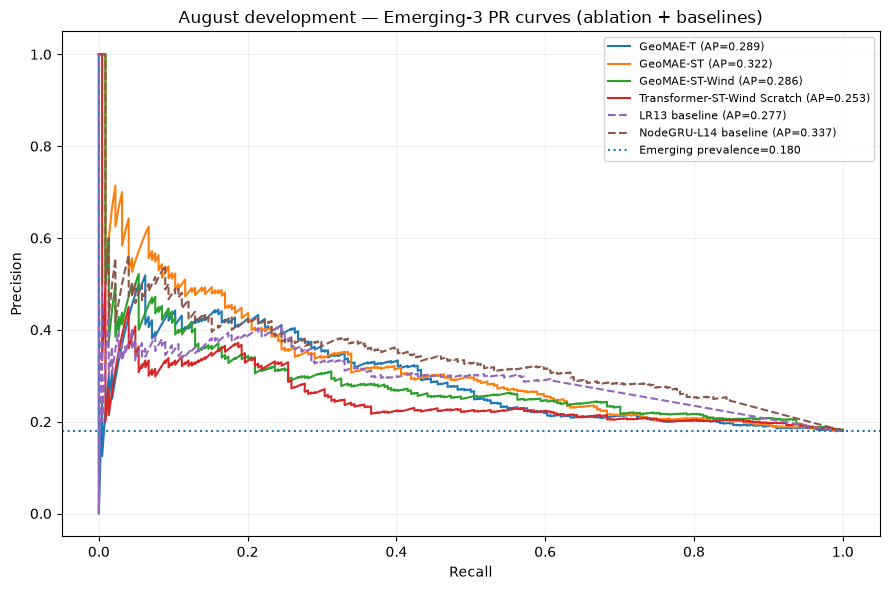

Saved c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_controlled_ablation\t2\figures\01_august_emerging_pr_ablation.png


In [25]:
# 24. Visualize all variants and baselines on SAME August Emerging-eligible rows
from sklearn.metrics import precision_recall_curve

em=val_eval["active_days_prev3_incl_t"].eq(0)
y=val_eval.loc[em,"target_fire_active_t1"].astype(int)
fig,ax=plt.subplots(figsize=(9,6))
for variant in VARIANT_ORDER:
    scores=val_eval.loc[em,variant]
    p,r,_=precision_recall_curve(y,scores)
    ap=average_precision_score(y,scores)
    ax.plot(r,p,label=f"{variant} (AP={ap:.3f})")
for name,col in [("LR13 baseline","LR13 baseline (matched train)")] + (
    [("NodeGRU-L14 baseline","nodegru_score")] if nodegru_available else []
):
    scores=val_eval.loc[em,col]
    p,r,_=precision_recall_curve(y,scores)
    ap=average_precision_score(y,scores)
    ax.plot(r,p,linestyle="--",label=f"{name} (AP={ap:.3f})")
ax.axhline(float(y.mean()),linestyle=":",label=f"Emerging prevalence={y.mean():.3f}")
ax.set(xlabel="Recall",ylabel="Precision",title="August development — Emerging-3 PR curves (ablation + baselines)")
ax.legend(fontsize=8,loc="best")
ax.grid(alpha=0.2)
fig.tight_layout()
fig_path=FIGURE_DIR/"01_august_emerging_pr_ablation.png"
fig.savefig(fig_path,dpi=180,bbox_inches="tight")
plt.show()
print("Saved",fig_path)

In [ ]:
# 25. Save all results, including unfavorable results and method lock
import json

for name, frame in [
    ("seed_results",seed_results),
    ("seed_summary",seed_summary),
    ("ensemble_summary",ensemble_summary),
    ("paired_component_deltas",paired),
    ("date_block_bootstrap_cis",bootstrap_table),
    ("august_baselines",baseline_summary),
    ("all_seed_predictions",all_pred),
    ("all_model_august_predictions",val_eval),
]:
    frame.to_csv(EXPORT_DIR/f"{name}.csv",index=False)
lock = {
    "task":"Emerging-3 next-day prediction and overall next-day detection",
    "period":"August development; previously used in earlier experiments",
    "training_end":"2026-07-31",
    "validation_start":"2026-08-01",
    "validation_end":"2026-08-31",
    "seeds":ABLATION_SEEDS,
    "finetune_epochs":ABLATION_EPOCHS,
    "head_warmup_epochs":ABLATION_WARMUP,
    "checkpoint":str(CHECKPOINT_PATH),
    "variants":VARIANT_ORDER,
    "quick_mode":QUICK_MODE,
    "restriction":"Do not use this development leaderboard to claim new untouched out-of-sample superiority",
}
(EXPORT_DIR/"ablation_method_lock.json").write_text(json.dumps(lock,indent=2),encoding="utf-8")
print("Exported to",EXPORT_DIR)

Exported to c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_controlled_ablation\t2\exports


: 

# Thesis-safe interpretation

- **GeoMAE can be your proposed research method** because the contribution is the masked-reconstruction approach to anomaly identification and a new wind-aware spatial downstream adaptation. This is a *method choice*, not proof of superiority.
- A **positive paired date-block CI** for an ablation indicates the associated input/pretraining helped on this August development experiment. If the interval crosses zero or is negative, report the uncertainty honestly.
- If **GeoMAE-ST-Wind** obtains the best Emerging PR-AUC among all models (including LR13 and NodeGRU), only claim it as the strongest *August development* performer, **not** as a previously unseen test winner.
- **September must not be used for additional tuning or to keep searching for a winning GeoMAE configuration.** Previous September work has already consumed it. A genuinely new time period or independent geography is needed for fresh confirmatory evidence.
- The original GeoMAE is for 3D point cloud data; this implementation is explicitly **GeoMAE-inspired**, not a literal implementation of the paper.

### Suggested supervisor narrative

> “Saya membandingkan GeoMAE dan Transformer dari scratch dengan backbone, data, seed, dan budget training yang sama. Lalu saya lakukan dua input ablation: menghilangkan neighbor context dan menghilangkan wind. Jadi saya bisa menunjukkan apakah tiap komponen membantu, bukan hanya membandingkan nama model. LR13 dan NodeGRU saya pertahankan sebagai baseline eksternal. Hasilnya saya laporkan lengkap untuk semua seed.”